# Projeto de Estatística Computacional
## Parte 1 — Contextualização e Pré-processamento (estatística descritiva)

Equipe:  

Wanderlânea Maria dos Santos Silva - Matrícula: 2022000412

 Iza Francine Carvalho Vieira - Matrícula: 2024001160

**Estrutura deste notebook**

1. Contextualização
2. Pré-processamento
   - 2.1 Leitura de dados
   - 2.2 Análise descritiva de duas das principais variáveis
   - 2.3 Transformação de variáveis
   - 2.4 Partição dos dados entre treino e validação



---
## 1. Contextualização

### O problema

Uma máquina de venda de café registra cada venda realizada: o horário, a forma de pagamento, o tipo de café e o valor pago. Para quem a opera, o **faturamento** é a medida central do negócio: ele define quanto é preciso comprar de insumos (grãos, leite, chocolate, copos), quanto de caixa está disponível e se vale a pena mudar preços ou cardápio. O faturamento, porém, **oscila bastante** de um dia para o outro e de um mês para o outro, o que dificulta o planejamento.

A grandeza de interesse deste projeto é o **faturamento mensal** (`monthly_sales`), definido como a soma dos valores pagos (`money`) em todas as vendas do mês. A pergunta central é:

> **O que explica as vendas e como prevê-las?**

### Por que a solução é importante

Um modelo que explique e preveja as vendas ajuda a planejar a compra de insumos com antecedência (evitando falta de produto e desperdício de itens perecíveis), a identificar quais dias e meses são mais fortes e a perceber mudanças de patamar do negócio. 

### Os dados e a unidade de análise

Foi utilizado o dataset [**Coffee sales**](https://www.kaggle.com/datasets/ihelon/coffee-sales/data), do Kaggle: **3.636 vendas**, de 01/03/2024 a 23/03/2025, com seis colunas originais (`date`, `datetime`, `cash_type`, `card`, `money`, `coffee_name`).


### A variável dependente

| Variável | Definição | Natureza |
|---|---|---|
| `daily_sales` | soma de `money` nas vendas do dia | Quantitativa contínua (**alvo**) |
| `monthly_sales` | soma de `money` nas vendas do mês (= soma dos `daily_sales` do mês) | Quantitativa contínua (nível mensal) |


---
## 2. Pré-processamento

### Configuração do ambiente



In [ ]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42  

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW_PATH = ROOT / "data" / "raw" / "coffee_sales.csv"
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
for pasta in (INTERIM_DIR, PROCESSED_DIR, FIG_DIR):
    pasta.mkdir(parents=True, exist_ok=True)

assert RAW_PATH.exists(), f"Arquivo não encontrado: {RAW_PATH}"

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def salvar_fig(nome):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

---
### 2.1 Leitura de dados

Lemos o arquivo **original** (`data/raw/coffee_sales.csv`):

In [ ]:
COLUNAS_DERIVADAS = ["order_quantity", "coffee_quantity", "coffee_demand", "monthly_sales"]

vendas = pd.read_csv(RAW_PATH)

vendas = vendas.drop(columns=[c for c in COLUNAS_DERIVADAS if c in vendas.columns])

vendas["date"] = pd.to_datetime(vendas["date"])
vendas["datetime"] = pd.to_datetime(vendas["datetime"])

display(vendas.head())
print("Formato (linhas, colunas):", vendas.shape)
vendas.info()

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.700,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.700,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.700,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.900,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.700,Latte


Formato (linhas, colunas): (3636, 6)
<class 'pandas.DataFrame'>
RangeIndex: 3636 entries, 0 to 3635
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         3636 non-null   datetime64[us]
 1   datetime     3636 non-null   datetime64[us]
 2   cash_type    3636 non-null   str           
 3   card         3547 non-null   str           
 4   money        3636 non-null   float64       
 5   coffee_name  3636 non-null   str           
dtypes: datetime64[us](2), float64(1), str(3)
memory usage: 170.6 KB


### Valores ausentes, duplicatas, período e dias sem registro

In [ ]:
ausentes = vendas.isna().sum().to_frame("ausentes")
ausentes["%"] = ausentes["ausentes"] / len(vendas) * 100
display(ausentes)

print("A ausência de 'card' coincide com o pagamento em dinheiro?")
display(pd.crosstab(vendas["card"].isna(), vendas["cash_type"], rownames=["card ausente"]))

print("Linhas duplicadas:", vendas.duplicated().sum())
print("Período:", vendas["date"].min().date(), "a", vendas["date"].max().date())

calendario = pd.date_range(vendas["date"].min(), vendas["date"].max())
sem_registro = calendario.difference(vendas["date"].unique())
print(f"Dias do período: {len(calendario)} | com vendas: {vendas['date'].nunique()} | sem nenhum registro: {len(sem_registro)}")
print("Dias sem registro:", [d.strftime("%d/%m/%Y") for d in sem_registro])

,ausentes,%
date,0,0.000
datetime,0,0.000
cash_type,0,0.000
card,89,2.448
money,0,0.000
coffee_name,0,0.000


A ausência de 'card' coincide com o pagamento em dinheiro?


cash_type,card,cash
card ausente,,
False,3547,0
True,0,89


Linhas duplicadas: 0
Período: 2024-03-01 a 2025-03-23
Dias do período: 388 | com vendas: 381 | sem nenhum registro: 7
Dias sem registro: ['01/05/2024', '04/05/2024', '05/05/2024', '27/11/2024', '01/01/2025', '19/01/2025', '23/01/2025']


**Interpretação.** O arquivo tem 3.636 vendas e 6 colunas, de 01/03/2024 a 23/03/2025. Não há linhas duplicadas. O único campo com valores ausentes é `card` (89 vendas, 2,4%), e esses 89 casos são **exatamente** as vendas pagas em dinheiro: não é falha de coleta, pagamento em dinheiro simplesmente não tem cartão associado. Como `card` é só um identificador anônimo, não foi preciso remover linhas nem preencher valores.

O período tem 388 dias, dos quais 381 têm vendas. Os 7 dias sem registro (alguns coincidem com feriados, como 01/05 e 01/01, mas isso é só uma hipótese) ficam fora do conjunto diário. O conjunto diário tem 381 linhas e preserva o total de vendas (conferido por `assert`).

### Construção do conjunto diário

Agrupamos as vendas por dia. Para cada dia calculamos:

- **`daily_sales`** (alvo): soma de `money`;
- **`order_quantity`**: número de vendas (pedidos) do dia. É a mesma variável criada no Teste 03, agora com uma linha por dia;
- **`ticket_medio`**: valor médio por venda;
- **`monthly_sales`**: soma de `money` no mês em que o dia está (a mesma definição do Teste 03);
- variáveis de calendário: `mes_ano`, `mes` (1 a 12), `dia_semana` e `dias_desde_inicio`.


In [ ]:
diario = (
    vendas.groupby("date")
    .agg(daily_sales=("money", "sum"), order_quantity=("money", "size"), ticket_medio=("money", "mean"))
    .reset_index()
)

meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
ordem_dias = ["seg", "ter", "qua", "qui", "sex", "sab", "dom"]

diario["mes_ano"] = diario["date"].dt.to_period("M").astype(str)
diario["mes"] = pd.Categorical(diario["date"].dt.month.map(dict(enumerate(meses, start=1))), categories=meses, ordered=True)
diario["dia_semana"] = pd.Categorical(diario["date"].dt.dayofweek.map(dict(enumerate(ordem_dias))), categories=ordem_dias, ordered=True)
diario["dias_desde_inicio"] = (diario["date"] - diario["date"].min()).dt.days
diario["monthly_sales"] = diario.groupby("mes_ano")["daily_sales"].transform("sum")

# conferência: a soma das vendas diárias deve ser igual ao total das vendas
assert np.isclose(diario["daily_sales"].sum(), vendas["money"].sum())

display(diario.head(8))
print("Formato do conjunto diário:", diario.shape)

,date,daily_sales,order_quantity,ticket_medio,mes_ano,mes,dia_semana,dias_desde_inicio,monthly_sales
0,2024-03-01,396.300,11,36.027,2024-03,mar,sex,0,7050.200
1,2024-03-02,228.100,7,32.586,2024-03,mar,sab,1,7050.200
2,2024-03-03,349.100,10,34.910,2024-03,mar,dom,2,7050.200
3,2024-03-04,135.200,4,33.800,2024-03,mar,seg,3,7050.200
4,2024-03-05,338.500,9,37.611,2024-03,mar,ter,4,7050.200
5,2024-03-06,170.200,5,34.040,2024-03,mar,qua,5,7050.200
6,2024-03-07,220.100,6,36.683,2024-03,mar,qui,6,7050.200
7,2024-03-08,265.500,8,33.188,2024-03,mar,sex,7,7050.200


Formato do conjunto diário: (381, 9)


### Dicionário de variáveis (conjunto diário)

| Variável | O que representa | Natureza | Papel nas próximas etapas |
|---|---|---|---|
| `date` | Data | Temporal | Identificador do dia (não é preditora) |
| `daily_sales` | Faturamento do dia | Quantitativa contínua | **Variável dependente (alvo)** |
| `monthly_sales` | Faturamento do mês do dia | Quantitativa contínua | Descartada como preditora (contém o alvo) |
| `order_quantity` | Número de vendas no dia | Quantitativa discreta | Descartada como preditora (ver 2.3); analisada em 2.2 |
| `ticket_medio` | Valor médio por venda no dia | Quantitativa contínua | Descartada como preditora (ver 2.3) |
| `mes_ano` | Mês e ano (ex.: 2024-03) | Qualitativa ordinal | Agrupamento para `monthly_sales` |
| `mes` | Mês do calendário (jan a dez) | Qualitativa ordinal | Preditora |
| `dia_semana` | Dia da semana (seg a dom) | Qualitativa ordinal | Preditora |
| `dias_desde_inicio` | Dias desde 01/03/2024 | Quantitativa discreta | Preditora (tendência) |

---
### 2.2 Análise descritiva de duas das principais variáveis

As duas variáveis em foco são:

1. **`daily_sales`**, a variável dependente (precedida de um olhar sobre `monthly_sales`, o faturamento mensal);
2. **`order_quantity`**, o número de pedidos do dia, que é a variável que mais se relaciona com o alvo (a justificativa numérica aparece na análise bivariada, 2.2.4).

#### 2.2.1 Faturamento mensal — `monthly_sales`


,dias_com_registro,monthly_sales,media_diaria
mes_ano,,,
2024-03,31,"7,050.20",227.43
2024-04,30,"6,720.56",224.02
2024-05,28,"9,063.42",323.69
2024-06,30,"7,758.76",258.63
2024-07,31,"6,915.94",223.09
2024-08,31,"7,613.84",245.61
2024-09,30,"9,988.64",332.95
2024-10,31,"13,891.16",448.10
2024-11,29,"8,590.54",296.23


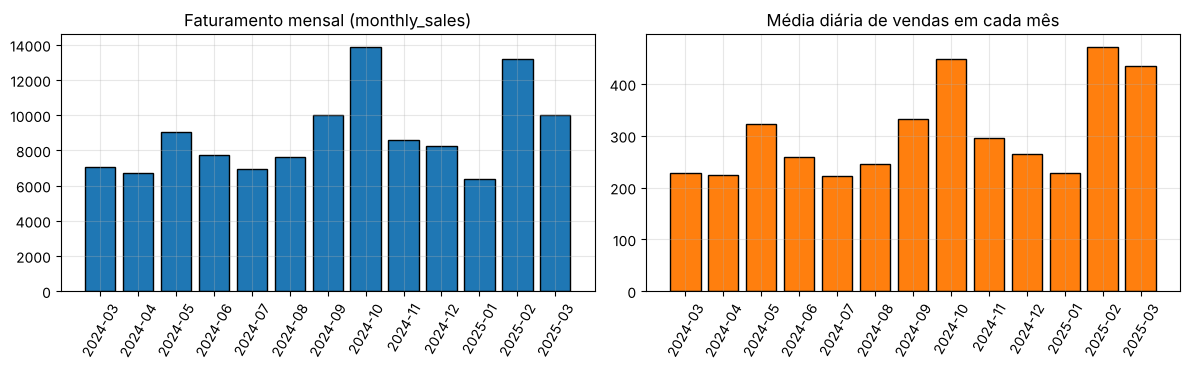

monthly_sales: média = 8,879.35 | mediana = 8,237.74 | desvio padrão = 2,376.56 | CV = 26.8% | mín = 6,398.86 | máx = 13,891.16


In [ ]:
mensal = (
    diario.groupby("mes_ano")
    .agg(dias_com_registro=("date", "size"), monthly_sales=("daily_sales", "sum"), media_diaria=("daily_sales", "mean"))
)
display(mensal.style.format({"dias_com_registro": "{:.0f}", "monthly_sales": "{:,.2f}", "media_diaria": "{:.2f}"}))

fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
eixos[0].bar(mensal.index, mensal["monthly_sales"], color="tab:blue", edgecolor="black")
eixos[0].set_title("Faturamento mensal (monthly_sales)")
eixos[1].bar(mensal.index, mensal["media_diaria"], color="tab:orange", edgecolor="black")
eixos[1].set_title("Média diária de vendas em cada mês")
for ax in eixos:
    ax.tick_params(axis="x", rotation=60)
salvar_fig("02_monthly_sales")

m = mensal["monthly_sales"]
print(f"monthly_sales: média = {m.mean():,.2f} | mediana = {m.median():,.2f} | desvio padrão = {m.std():,.2f} "
      f"| CV = {m.std() / m.mean():.1%} | mín = {m.min():,.2f} | máx = {m.max():,.2f}")

**Interpretação.** O faturamento mensal tem média de 8.879,35, mediana de 8.237,74 e desvio padrão de 2.376,56 (CV de 26,8%), com valores entre 6.398,86 (jan/2025) e 13.891,16 (out/2024). Dois meses se destacam acima dos demais: outubro de 2024 (13.891,16) e fevereiro de 2025 (13.215,48). 

#### 2.2.2 Variável dependente — `daily_sales`

**Distribuição de frequências**, em classes de largura 100:

,freq. absoluta,freq. relativa,porcentagem (%),% acumulada
daily_sales,,,,
"(0, 100]",26,0.0682,6.8,6.8
"(100, 200]",81,0.2126,21.3,28.1
"(200, 300]",106,0.2782,27.8,55.9
"(300, 400]",82,0.2152,21.5,77.4
"(400, 500]",36,0.0945,9.4,86.9
"(500, 600]",31,0.0814,8.1,95.0
"(600, 700]",12,0.0315,3.1,98.2
"(700, 800]",6,0.0157,1.6,99.7
"(800, 900]",1,0.0026,0.3,100.0


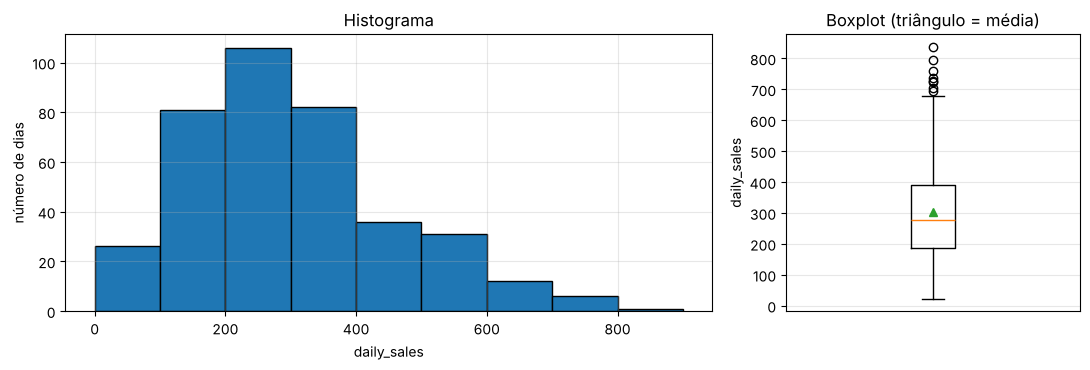

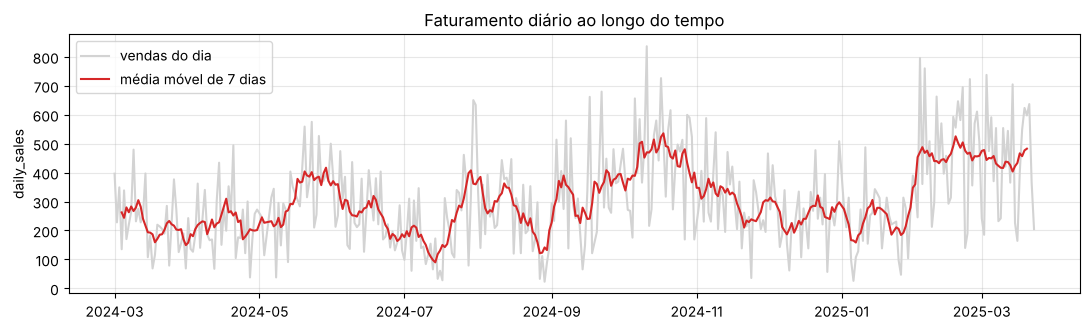

In [ ]:
def tabela_frequencias(x, limites):
    classes = pd.cut(x, bins=limites)
    f = classes.value_counts(sort=False)
    return pd.DataFrame({
        "freq. absoluta": f,
        "freq. relativa": f / len(x),
        "porcentagem (%)": f / len(x) * 100,
        "% acumulada": f.cumsum() / len(x) * 100,
    })


fmt = {"freq. absoluta": "{:.0f}", "freq. relativa": "{:.4f}", "porcentagem (%)": "{:.1f}", "% acumulada": "{:.1f}"}
display(tabela_frequencias(diario["daily_sales"], np.arange(0, 1000, 100)).style.format(fmt))

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2.2, 1]})
eixos[0].hist(diario["daily_sales"], bins=np.arange(0, 1000, 100), color="tab:blue", edgecolor="black")
eixos[0].set_xlabel("daily_sales")
eixos[0].set_ylabel("número de dias")
eixos[0].set_title("Histograma")
eixos[1].boxplot(diario["daily_sales"], showmeans=True)
eixos[1].set_ylabel("daily_sales")
eixos[1].set_xticks([])
eixos[1].set_title("Boxplot (triângulo = média)")
salvar_fig("02_daily_sales_univariado")

# evolução no tempo, com média móvel de 7 registros
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(diario["date"], diario["daily_sales"], color="lightgray", label="vendas do dia")
ax.plot(diario["date"], diario["daily_sales"].rolling(7, center=True).mean(), color="tab:red", label="média móvel de 7 dias")
ax.set_ylabel("daily_sales")
ax.set_title("Faturamento diário ao longo do tempo")
ax.legend()
salvar_fig("02_daily_sales_serie")

**Medidas de posição e de dispersão** de `daily_sales` e de `order_quantity` (analisada na próxima subseção). A moda não é informativa para uma variável contínua com muitos valores distintos, por isso aparece só para `order_quantity`.

In [ ]:
def resumo(x, moda=True):
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    limite_sup, limite_inf = q3 + 1.5 * (q3 - q1), q1 - 1.5 * (q3 - q1)
    r = {
        "n": x.size, "média": x.mean(), "mediana": x.median(),
        "moda": x.mode().iloc[0] if moda else np.nan,
        "mínimo": x.min(), "máximo": x.max(), "amplitude": x.max() - x.min(),
        "variância": x.var(), "desvio padrão": x.std(), "CV (%)": x.std() / x.mean() * 100,
        "Q1": q1, "Q3": q3, "IQR": q3 - q1, "assimetria": x.skew(), "curtose": x.kurt(),
        "outliers (critério do boxplot)": int(((x > limite_sup) | (x < limite_inf)).sum()),
    }
    return pd.Series(r)


tabela_resumo = pd.DataFrame({
    "daily_sales": resumo(diario["daily_sales"], moda=False),
    "order_quantity": resumo(diario["order_quantity"]),
})
display(tabela_resumo)

,daily_sales,order_quantity
n,381.000,381.000
média,302.970,9.543
mediana,276.280,9.000
moda,NaN,8.000
mínimo,23.020,1.000
máximo,836.660,26.000
amplitude,813.640,25.000
variância,25541.226,26.028
desvio padrão,159.816,5.102
CV (%),52.750,53.459


**Interpretação.** O faturamento diário tem média de 302,97 e mediana de 276,28, com desvio padrão de 159,82 (variância de 25.541,23), o que dá um coeficiente de variação de 52,8%: uma dispersão **alta**. Os valores vão de 23,02 a 836,66 (amplitude de 813,64) e a metade central dos dias fica entre 187,12 e 389,92 (IQR de 202,80). A classe mais frequente é a de 200 a 300 (27,8% dos dias); 55,9% dos dias faturam até 300 e 77,4% até 400, e apenas um dia passa de 800. A média acima da mediana e a assimetria de 0,72 indicam cauda à direita, e o critério do boxplot aponta 8 dias atípicos, todos **acima** de 694,12 (os maiores: 836,66 em 11/10/2024 e 796,00 em 03/02/2025). A

#### 2.2.3 Variável explicativa — `order_quantity` (quantitativa discreta)

Número de vendas do dia. Distribuição de frequências em classes de largura 4 e gráficos:

,freq. absoluta,freq. relativa,porcentagem (%),% acumulada
order_quantity,,,,
"(0, 4]",57,0.1496,15.0,15.0
"(4, 8]",129,0.3386,33.9,48.8
"(8, 12]",103,0.2703,27.0,75.9
"(12, 16]",51,0.1339,13.4,89.2
"(16, 20]",26,0.0682,6.8,96.1
"(20, 24]",13,0.0341,3.4,99.5
"(24, 28]",2,0.0052,0.5,100.0


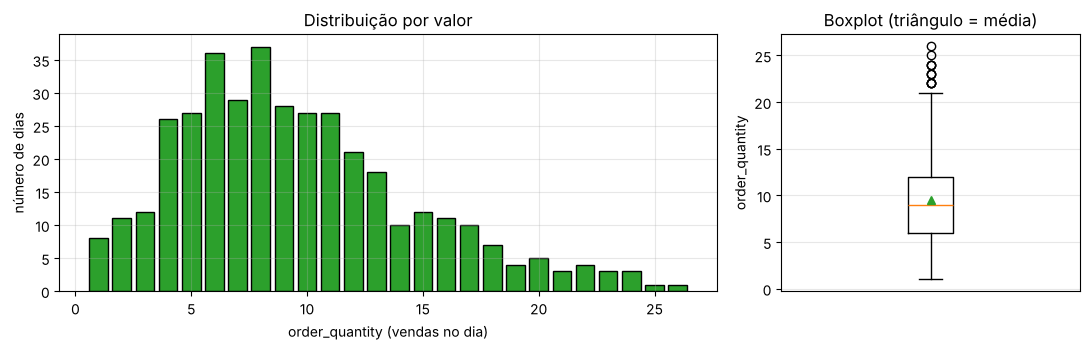

In [ ]:
display(tabela_frequencias(diario["order_quantity"], range(0, 32, 4)).style.format(fmt))

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
contagem = diario["order_quantity"].value_counts().sort_index()
eixos[0].bar(contagem.index, contagem.values, color="tab:green", edgecolor="black")
eixos[0].set_xlabel("order_quantity (vendas no dia)")
eixos[0].set_ylabel("número de dias")
eixos[0].set_title("Distribuição por valor")
eixos[1].boxplot(diario["order_quantity"], showmeans=True)
eixos[1].set_ylabel("order_quantity")
eixos[1].set_xticks([])
eixos[1].set_title("Boxplot (triângulo = média)")
salvar_fig("02_order_quantity_univariado")

**Interpretação.** O número de vendas por dia tem média de 9,54, mediana de 9 e moda de 8, com desvio padrão de 5,10 (CV de 53,5%, alto). Os valores vão de 1 a 26, a metade central dos dias tem de 6 a 12 vendas (IQR de 6) e a assimetria é de 0,78, à direita. A classe mais frequente é a de 5 a 8 vendas (33,9% dos dias); 48,8% dos dias têm até 8 vendas e 75,9% até 12. O critério do boxplot marca 12 dias como atípicos (acima de 21 vendas). Repare que a **forma** da distribuição é muito parecida com a de `daily_sales` (assimetria à direita, CV em torno de 53%), o que antecipa a relação forte vista a seguir. (No Teste 03 a análise era feita por venda, e por isso a média dava 12,26; por dia, o valor típico é menor, porque dias movimentados deixam de ser contados várias vezes.)

#### 2.2.4 Análise bivariada, com foco na variável dependente

**`daily_sales` × `order_quantity`** (quantitativa × quantitativa): diagrama de dispersão e coeficientes de correlação de Pearson (relação linear) e de Spearman (relação monotônica, menos sensível a valores extremos).

Pearson:  r = 0.987 (p = 6.4e-305)
Spearman: rho = 0.987 (p = 3.5e-300)
Reta ajustada: daily_sales = 7.81 + 30.93 x order_quantity
Para comparação, correlação com o valor médio por venda (ticket_medio): r = 0.019


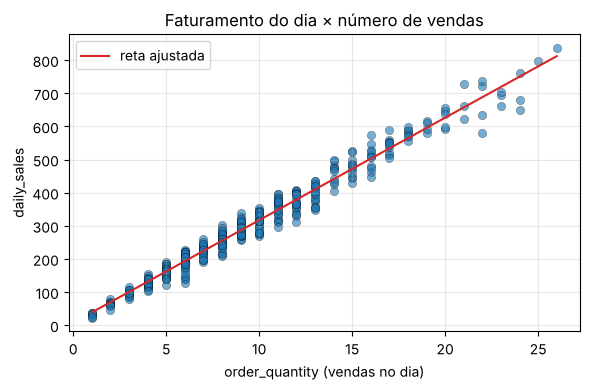

In [ ]:
r_p, p_p = stats.pearsonr(diario["order_quantity"], diario["daily_sales"])
r_s, p_s = stats.spearmanr(diario["order_quantity"], diario["daily_sales"])
r_t, _ = stats.pearsonr(diario["ticket_medio"], diario["daily_sales"])
inclinacao, intercepto = np.polyfit(diario["order_quantity"], diario["daily_sales"], 1)

print(f"Pearson:  r = {r_p:.3f} (p = {p_p:.1e})")
print(f"Spearman: rho = {r_s:.3f} (p = {p_s:.1e})")
print(f"Reta ajustada: daily_sales = {intercepto:.2f} + {inclinacao:.2f} x order_quantity")
print(f"Para comparação, correlação com o valor médio por venda (ticket_medio): r = {r_t:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(diario["order_quantity"], diario["daily_sales"], alpha=0.6, edgecolor="black", linewidth=0.3)
xs = np.array([diario["order_quantity"].min(), diario["order_quantity"].max()])
ax.plot(xs, intercepto + inclinacao * xs, color="tab:red", label="reta ajustada")
ax.set_xlabel("order_quantity (vendas no dia)")
ax.set_ylabel("daily_sales")
ax.set_title("Faturamento do dia × número de vendas")
ax.legend()
salvar_fig("02_dispersao_vendas_pedidos")

**Interpretação.** A relação é **muito forte e linear**: Pearson e Spearman valem 0,987, e a reta ajustada indica que cada venda adicional no dia acrescenta cerca de 30,93 ao faturamento (valor próximo do preço médio por venda, 31,75, na amostra de vendas). O número de vendas explica cerca de 97,5% da variação do faturamento diário (r² = 0,987² ≈ 0,975). Já o valor médio por venda quase não se relaciona com o faturamento (r = 0,02): **o que faz um dia render mais é vender mais, e não vender mais caro**. 

**`daily_sales` × `dia_semana`** (quantitativa × qualitativa ordinal):

,count,mean,std,min,25%,50%,75%,max
dia_semana,,,,,,,,
seg,55.000,325.911,181.502,25.960,222.510,297.320,396.040,796.000
ter,55.000,338.861,155.858,32.820,226.960,338.500,440.120,661.760
qua,52.000,309.490,170.654,27.920,193.855,279.200,384.170,760.240
qui,54.000,305.137,149.127,23.020,204.870,282.640,383.925,726.460
sex,56.000,308.173,171.670,67.600,181.365,265.990,398.135,836.660
sab,55.000,276.046,127.487,37.720,184.180,262.560,353.660,579.940
dom,54.000,256.631,150.027,35.760,156.750,224.540,344.605,679.880


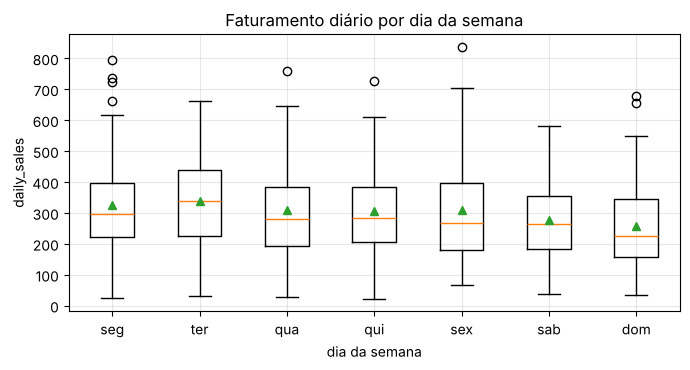

Kruskal-Wallis (dia da semana): H = 10.9, p = 0.091


In [ ]:
display(diario.groupby("dia_semana", observed=True)["daily_sales"].describe())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.boxplot([diario.loc[diario["dia_semana"] == d, "daily_sales"] for d in ordem_dias], tick_labels=ordem_dias, showmeans=True)
ax.set_xlabel("dia da semana")
ax.set_ylabel("daily_sales")
ax.set_title("Faturamento diário por dia da semana")
salvar_fig("02_daily_sales_por_dia_semana")

h, p = stats.kruskal(*[diario.loc[diario["dia_semana"] == d, "daily_sales"] for d in ordem_dias])
print(f"Kruskal-Wallis (dia da semana): H = {h:.1f}, p = {p:.3f}")

**Interpretação.** O faturamento médio é mais alto na terça (338,86) e na segunda (325,91) e mais baixo no sábado (276,05) e, principalmente, no domingo (256,63, mediana de 224,54): o fim de semana rende menos. Porém, os boxplots se sobrepõem bastante (desvios padrão entre 127 e 182) e o teste de Kruskal-Wallis não é conclusivo a 5% (H = 10,9, p = 0,091). O dia da semana, portanto, mostra uma tendência, mas **com evidência fraca** de que explique o faturamento.

**`daily_sales` × mês** (quantitativa × qualitativa ordinal), com um boxplot para cada um dos 13 meses:

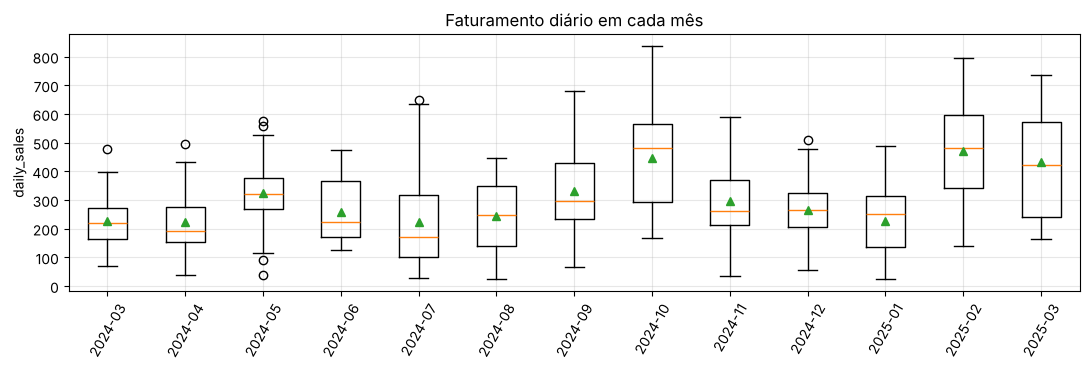

Kruskal-Wallis (mês): H = 92.4, p = 1.7e-14


In [ ]:
ordem_mes_ano = sorted(diario["mes_ano"].unique())

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.boxplot([diario.loc[diario["mes_ano"] == m, "daily_sales"] for m in ordem_mes_ano], tick_labels=ordem_mes_ano, showmeans=True)
ax.tick_params(axis="x", rotation=60)
ax.set_ylabel("daily_sales")
ax.set_title("Faturamento diário em cada mês")
salvar_fig("02_daily_sales_por_mes")

h, p = stats.kruskal(*[diario.loc[diario["mes_ano"] == m, "daily_sales"] for m in ordem_mes_ano])
print(f"Kruskal-Wallis (mês): H = {h:.1f}, p = {p:.1e}")

**Interpretação.** O mês faz muito mais diferença que o dia da semana: o teste de Kruskal-Wallis rejeita com folga a hipótese de faturamento diário igual em todos os meses (H = 92,4, p ≈ 10⁻¹⁴). A mediana e a dispersão variam bastante de um mês para o outro, e outubro/2024, fevereiro/2025 e março/2025 formam um patamar claramente acima do resto. Como boa parte da variação do faturamento está entre os meses, `mes` é uma preditora relevante. A ressalva é que, com um único ano de dados, o efeito do "mês" se confunde com o efeito do "período" (fevereiro, por exemplo, só aparece em 2025).